# 01 · Auditoría de riesgo de re-identificación ($k$-anonimato, $l$-diversidad, $t$-cercanía)

**Objetivo:** cuantificar empíricamente el riesgo de re-identificación de la tabla `oulad_analitico` (ventana de 60 días) antes de exponerla a analistas o a investigación externa, y justificar técnicamente la adopción de Privacidad Diferencial ($\epsilon$-DP).

**Unidad de análisis:** cada fila es una matrícula (`id_student` × `code_module` × `code_presentation`). Un mismo estudiante puede tener varias matrículas.

**Marco:** Sweeney (2002) para $k$-anonimato; Machanavajjhala et al. (2007) para $l$-diversidad; Li et al. (2007) para $t$-cercanía; Dwork et al. (2006) para $\epsilon$-DP. Riesgos alineados con LINDDUN (*linkability*, *identifiability*) y con el principio de proporcionalidad de la Ley N.° 29733.

In [1]:
import itertools
import sqlite3

import numpy as np
import pandas as pd

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

DB_PATH = "../db/oulad_proyecto.db"
con = sqlite3.connect(DB_PATH)
df = pd.read_sql("SELECT * FROM oulad_analitico", con)
identidad = pd.read_sql("SELECT * FROM estudiantes_identidad", con)

print(f"Matrículas: {len(df):,} | Estudiantes únicos: {df['id_student'].nunique():,}")
df.head()

Matrículas: 32,593 | Estudiantes únicos: 28,785


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result,target_aprobado,date_registration,promedio_notas_60d,entregas_60d,retraso_promedio_60d,total_clics_60d,dias_activos_60d
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass,1,-159.0,81.5,2,-1.0,529,18
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass,1,-53.0,69.0,2,0.5,669,26
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn,0,-92.0,0.0,0,0.0,281,12
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass,1,-52.0,71.5,2,-2.5,816,41
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass,1,-176.0,69.0,1,7.0,605,28


## 1. Clasificación de atributos

| Categoría | Atributos | Ubicación | Tratamiento |
|---|---|---|---|
| **Identificadores directos** | `nombre_completo`, `dni`, `correo_institucional` | `estudiantes_identidad` (tabla separada) | Nunca se exponen a analistas; acceso restringido por RBAC. |
| **Identificador seudónimo** | `id_student` | `oulad_analitico` | Llave de enlace con la identidad; seudonimización ≠ anonimización (sigue siendo dato personal). |
| **Cuasi-identificadores (QI)** | `region`, `age_band`, `gender`, `highest_education`, `imd_band` | `oulad_analitico` | Inofensivos por separado, identificantes en combinación. |
| **QI contextuales** | `code_module`, `code_presentation` (y en menor grado `studied_credits`, `num_of_prev_attempts`) | `oulad_analitico` | Conocidos por compañeros, docentes o listas de clase; amplifican el riesgo de enlace. |
| **Atributos sensibles** | `target_aprobado`, `disability` | `oulad_analitico` | `disability` es un dato sensible (salud) según la Ley 29733, Art. 2.5; el rendimiento académico tiene impacto reputacional. |
| **Atributos conductuales** | `promedio_notas_60d`, `entregas_60d`, `retraso_promedio_60d`, `total_clics_60d`, `dias_activos_60d`, `date_registration` | `oulad_analitico` | Variables predictoras; continuas y potencialmente únicas (huella de comportamiento). |

In [2]:
QI = ["region", "age_band", "gender", "highest_education", "imd_band"]
QI_EXT = QI + ["code_module", "code_presentation"]
SENSIBLES = ["target_aprobado", "disability"]

df[QI_EXT].nunique().rename("cardinalidad").to_frame().T

,region,age_band,gender,highest_education,imd_band,code_module,code_presentation
cardinalidad,13,3,2,5,11,7,4


## 2. $k$-anonimato empírico

Una tabla es $k$-anónima si cada combinación de QI (clase de equivalencia) contiene al menos $k$ registros. Un registro con $k=1$ es **singularizable**: basta conocer sus QI para aislarlo.

In [3]:
def reporte_k(data: pd.DataFrame, qi: list, etiqueta: str) -> dict:
    tam = data.groupby(qi, observed=True)[qi[0]].transform("size")
    return {
        "escenario": etiqueta,
        "clases": data.groupby(qi, observed=True).ngroups,
        "k_min": int(tam.min()),
        "k_mediana": float(tam.median()),
        "registros_k=1": int((tam == 1).sum()),
        "registros_k<5": int((tam < 5).sum()),
        "%_k<5": round(100 * (tam < 5).mean(), 2),
    }

estudiantes = df.drop_duplicates("id_student")
resumen_k = pd.DataFrame([
    reporte_k(df, QI, "QI base · matrículas"),
    reporte_k(estudiantes, QI, "QI base · estudiantes únicos"),
    reporte_k(df, QI + ["code_module"], "QI base + curso · matrículas"),
    reporte_k(df, QI_EXT, "QI base + curso + semestre · matrículas"),
])
resumen_k

,escenario,clases,k_min,k_mediana,registros_k=1,registros_k<5,%_k<5
0,QI base · matrículas,1509,5,33.0,0,0,0.00
1,QI base · estudiantes únicos,1509,2,29.0,0,287,1.00
2,QI base + curso · matrículas,7041,1,8.0,2085,9510,29.18
3,QI base + curso + semestre · matrículas,14602,1,3.0,7396,22103,67.82


In [4]:
df["k_base"] = df.groupby(QI)[QI[0]].transform("size")
df["k_ext"] = df.groupby(QI_EXT)[QI[0]].transform("size")
bins = [0, 1, 4, 10, 50, np.inf]
labels = ["k=1", "2-4", "5-10", "11-50", ">50"]
pd.DataFrame({
    "QI base": pd.cut(df["k_base"], bins, labels=labels).value_counts().sort_index(),
    "QI base + curso + semestre": pd.cut(df["k_ext"], bins, labels=labels).value_counts().sort_index(),
})

,QI base,QI base + curso + semestre
k=1,0,7396
2-4,0,14707
5-10,3914,9121
11-50,19695,1369
>50,8984,0


**Lectura:**
- Con los 5 QI base, la versión pública de OULAD ya cumple $k \geq 5$ a nivel de matrícula. Esto es consistente con la anonimización que aplicó la Open University antes de publicar el dataset: el *release* fue diseñado para resistir exactamente este conjunto de QI.
- Esa protección **no sobrevive al contexto**: el curso y el semestre de un estudiante no son secretos (listas de clase, grupos de WhatsApp, compañeros, docentes). Al añadirlos, la mayoría de matrículas cae por debajo de $k=5$ y miles quedan con $k=1$.
- Conclusión: el $k$-anonimato es una propiedad **relativa al modelo de adversario** que se asume, no una propiedad intrínseca del dato.

## 3. $l$-diversidad y $t$-cercanía de los atributos sensibles

Aunque una clase tenga $k \geq 5$, si todos sus miembros comparten el mismo valor sensible el atacante lo infiere sin necesidad de singularizar a nadie (**ataque de homogeneidad**).
- **$l$-diversidad distinta:** número de valores distintos del atributo sensible en la clase. Para atributos binarios, $l=1$ implica revelación total.
- **$t$-cercanía:** distancia entre la distribución del atributo en la clase y la distribución global. Para un atributo binario, la *Earth Mover's Distance* se reduce a $|p_{clase} - p_{global}|$.

In [5]:
def auditoria_l_t(data: pd.DataFrame, qi: list, sensible: str, positivo) -> pd.Series:
    x = (data[sensible] == positivo).astype(int)
    g = x.groupby([data[c] for c in qi])
    clases = pd.DataFrame({"n": g.size(), "l": g.nunique(), "p": g.mean()})
    p_global = x.mean()
    clases["t"] = (clases["p"] - p_global).abs()
    homog = clases["l"] == 1
    return pd.Series({
        "p_global": round(p_global, 3),
        "clases": len(clases),
        "clases_l=1": int(homog.sum()),
        "registros_en_clases_l=1": int(clases.loc[homog, "n"].sum()),
        "%_registros_l=1": round(100 * clases.loc[homog, "n"].sum() / len(data), 2),
        "t_max": round(clases["t"].max(), 3),
        "clases_t>0.2": int((clases["t"] > 0.2).sum()),
    })

filas = {}
for qi_nombre, qi in [("QI base", QI), ("QI base + curso + semestre", QI_EXT)]:
    filas[(qi_nombre, "target_aprobado")] = auditoria_l_t(df, qi, "target_aprobado", 1)
    filas[(qi_nombre, "disability")] = auditoria_l_t(df, qi, "disability", "Y")
pd.DataFrame(filas).T

p_global   clases  clases_l=1  registros_en_clases_l=1  %_registros_l=1  t_max  clases_t>0.2
QI base                    target_aprobado     0.472   1509.0        26.0                    168.0             0.52  0.528         384.0
                           disability          0.097   1509.0      1105.0                  15628.0            47.95  0.903          74.0
QI base + curso + semestre target_aprobado     0.472  14602.0      9907.0                  13686.0            41.99  0.528       10793.0
                           disability          0.097  14602.0     12696.0                  23727.0            72.80  0.903        1668.0

In [6]:
# Ejemplo concreto: clases con k>=5 (QI base) pero homogéneas en disability.
g = df.groupby(QI)
clases_base = pd.DataFrame({
    "k": g.size(),
    "l_disability": g["disability"].nunique(),
    "valor_disability": g["disability"].first(),
    "l_target": g["target_aprobado"].nunique(),
    "tasa_aprobacion": g["target_aprobado"].mean().round(2),
})
print("Clases con k>=5 homogéneas en target_aprobado:", int(clases_base.query("k >= 5 and l_target == 1").shape[0]))
clases_base.query("k >= 5 and (l_disability == 1 or l_target == 1)").sort_values("k", ascending=False).head(8)

Clases con k>=5 homogéneas en target_aprobado: 26


k  l_disability valor_disability  l_target  tasa_aprobacion
region               age_band gender highest_education     imd_band                                                                 
South Region         0-35     M      A Level or Equivalent 70-80%       79             1                N         2             0.56
North Western Region 0-35     M      A Level or Equivalent 20-30%       68             1                N         2             0.43
North Region         0-35     M      HE Qualification      Desconocido  67             1                N         2             0.78
                                     A Level or Equivalent 10-20        67             1                N         2             0.36
West Midlands Region 0-35     M      A Level or Equivalent 30-40%       64             1                N         2             0.47
South Region         0-35     M      Lower Than A Level    70-80%       64             1                N         2             0.36
London Region        0-35     M      A Level or Equivalent 40-50%       63             1                N         2             0.48
Scotland             0-35     M      HE Qualification      80-90%       63             1                N         2             0.63

In [7]:
# Revelación positiva de un dato de salud: clases homogéneas con disability = 'Y'.
for nombre, qi in [("QI base", QI), ("QI base + curso + semestre", QI_EXT)]:
    g = df.groupby(qi)["disability"]
    c = pd.DataFrame({"n": g.size(), "l": g.nunique(), "v": g.first()})
    y = c.query("l == 1 and v == 'Y'")
    print(f"{nombre:<28} clases l=1 con disability='Y': {len(y):>5} | estudiantes expuestos: {int(y['n'].sum()):>5}")

QI base                      clases l=1 con disability='Y':     4 | estudiantes expuestos:    21
QI base + curso + semestre   clases l=1 con disability='Y':   561 | estudiantes expuestos:   633


**Lectura:** incluso en el escenario en que el $k$-anonimato se cumple (QI base, $k \geq 5$), existen clases homogéneas en las que se puede inferir el resultado académico o la condición de discapacidad de **todos** sus miembros. Cuando `valor_disability = 'Y'` en una clase con $l=1$, se revela un dato de salud, que es especialmente protegido (Ley 29733, Art. 2.5 y Art. 13.6).

## 4. Simulación de ataque de enlace (*linkage attack*)

**Escenario de amenaza (LINDDUN: *Linkability* → *Identifiability*):** un tercero obtiene un **padrón externo** con nombre, DNI y atributos demográficos de una muestra de estudiantes. Algunas fuentes plausibles son una filtración de la lista de matrícula de un curso, perfiles de redes profesionales o una encuesta de bienestar. Por separado, accede a la tabla `oulad_analitico`, que se publicó "anonimizada" sin nombres ni DNI. El atacante cruza ambas tablas por los QI.

`imd_band` es un índice de privación por código postal, así que se deriva de la dirección del estudiante.

In [8]:
rng = np.random.default_rng(7)

# Tabla publicada: sin identificadores directos ni id_student.
publicada = df.drop(columns=["id_student", "k_base", "k_ext"]).copy()
publicada["_fila"] = np.arange(len(publicada))   # solo para verificar el ataque (oculto al atacante)
verdad = df["id_student"].to_numpy()

# Padrón externo simulado: 3 000 matrículas con identidad real + QI.
idx = rng.choice(len(df), size=3000, replace=False)
padron = (df.iloc[idx][["id_student"] + QI_EXT]
          .merge(identidad, on="id_student")
          .rename(columns={"id_student": "_id_real"}))
padron[["nombre_completo", "dni"] + QI_EXT].head()

,nombre_completo,dni,region,age_band,gender,highest_education,imd_band,code_module,code_presentation
0,Irma Elizondo Pérez,47691306,South West Region,0-35,M,Lower Than A Level,60-70%,EEE,2013J
1,Felipe Vargas Araya,59514301,East Midlands Region,35-55,M,Lower Than A Level,60-70%,DDD,2013J
2,Elizabeth Pérez Gutiérrez,75779790,West Midlands Region,35-55,M,A Level or Equivalent,40-50%,DDD,2013B
3,Wladimir Uribe Narváez,17993238,North Western Region,0-35,F,A Level or Equivalent,70-80%,CCC,2014B
4,Sonia Gómez Alba,28626869,Ireland,35-55,M,Lower Than A Level,10-20,BBB,2014J


In [9]:
def ataque_enlace(padron: pd.DataFrame, publicada: pd.DataFrame, qi: list) -> tuple[pd.DataFrame, dict]:
    cruce = padron.merge(publicada, on=qi, how="inner")
    candidatos = cruce.groupby("dni")["_fila"].transform("size")
    unicos = cruce[candidatos == 1].copy()
    unicos["acierto"] = verdad[unicos["_fila"]] == unicos["_id_real"]
    metricas = {
        "QI usados": " + ".join(qi) if len(qi) <= 5 else "QI base + curso + semestre",
        "objetivos en padrón": padron["dni"].nunique(),
        "re-identificados (match único)": unicos["dni"].nunique(),
        "% re-identificación": round(100 * unicos["dni"].nunique() / padron["dni"].nunique(), 2),
        "precisión del match único": round(100 * unicos["acierto"].mean(), 2) if len(unicos) else np.nan,
    }
    return unicos, metricas

_, m_base = ataque_enlace(padron, publicada, QI)
reid, m_ext = ataque_enlace(padron, publicada, QI_EXT)
pd.DataFrame([m_base, m_ext])

,QI usados,objetivos en padrón,re-identificados (match único),% re-identificación,precisión del match único
0,region + age_band + gender + highest_education...,2972,0,0.00,NaN
1,QI base + curso + semestre,2972,665,22.38,100.0


In [10]:
# Evidencia: atributos sensibles revelados para víctimas re-identificadas (datos sintéticos).
reid[["nombre_completo", "dni", "code_module", "code_presentation", "disability",
      "target_aprobado", "promedio_notas_60d", "total_clics_60d", "acierto"]].head(10)

,nombre_completo,dni,code_module,code_presentation,disability,target_aprobado,promedio_notas_60d,total_clics_60d,acierto
7,Elizabeth Pérez Gutiérrez,75779790,DDD,2013B,N,0,51.5,69,True
27,Lucas Camargo Vargas,21923420,FFF,2013B,N,1,93.5,1031,True
28,Giuliana Zamora Armenta,54268662,AAA,2013J,N,1,55.0,957,True
35,Astrid Tapia Collazo,79305545,BBB,2013J,N,1,92.0,85,True
49,María Jaramillo Correa,65083697,CCC,2014J,N,0,0.0,154,True
61,Andrea González Guerrero,49544193,CCC,2014B,N,0,0.0,22,True
71,Esther Santacruz Martínez,69931196,EEE,2014B,N,1,90.0,750,True
95,José Obando Díaz,77651858,CCC,2014J,N,1,89.0,272,True
118,Claudia Jurado Aragón,78345762,BBB,2013J,Y,1,85.0,52,True
135,Enrique Madrigal Rivera,69599399,CCC,2014J,N,1,100.0,2977,True


In [11]:
reveladas = reid.drop_duplicates("dni")
print(f"Víctimas re-identificadas: {len(reveladas):,}")
print(f"  · con discapacidad revelada (disability='Y'): {(reveladas['disability'] == 'Y').sum():,}")
print(f"  · con resultado 'no aprobado' revelado:        {(reveladas['target_aprobado'] == 0).sum():,}")

Víctimas re-identificadas: 665
  · con discapacidad revelada (disability='Y'): 38
  · con resultado 'no aprobado' revelado:        335


**Lectura:** con los QI base el cruce no produce ningún *match* único, porque el $k \geq 5$ del *release* cumple su función. Al sumar curso y semestre, que cualquier compañero conoce, cerca de 1 de cada 5 personas del padrón queda re-identificada con **precisión del 100 %**. El atacante obtiene la condición de discapacidad, el resultado académico y la huella conductual (notas, clics) de personas con nombre y DNI. Esto es una brecha de datos sensibles bajo la Ley 29733 y debe notificarse a la ANPD en 48 h según el DS 016-2024-JUS.

## 5. Generalización hasta $k \geq 5$: costo en utilidad analítica

Se aplica **generalización de dominio completo** (Samarati, 2001) con jerarquías por QI. Se exploran **todas** las combinaciones de niveles del retículo y se buscan las que alcanzan $k \geq 5$ sin suprimir registros.

| QI | Nivel 0 | Nivel 1 | Nivel 2 |
|---|---|---|---|
| `region` | 13 regiones | macro-zona (Norte, Centro, Sur, Escocia, Gales, Irlanda) | `*` |
| `age_band` | 3 bandas | `0-35` / `35+` | `*` |
| `gender` | F / M | `*` | — |
| `highest_education` | 5 niveles | superior / no superior | `*` |
| `imd_band` | 10 deciles + desconocido | terciles (bajo / medio / alto) + desconocido | `*` |
| `code_module` | 7 cursos | área (CS / STEM) | `*` |
| `code_presentation` | 4 semestres | año | `*` |

In [12]:
MACRO = {
    "North Region": "Norte", "North Western Region": "Norte", "Yorkshire Region": "Norte",
    "East Midlands Region": "Centro", "West Midlands Region": "Centro", "East Anglian Region": "Centro",
    "London Region": "Sur", "South East Region": "Sur", "South Region": "Sur", "South West Region": "Sur",
    "Scotland": "Escocia", "Wales": "Gales", "Ireland": "Irlanda",
}

def imd_tercil(v: str) -> str:
    if v == "Desconocido":
        return v
    inf = int(v.split("-")[0].rstrip("%"))
    return "bajo" if inf < 30 else ("medio" if inf < 70 else "alto")

JERARQUIAS = {
    "region": [lambda s: s, lambda s: s.map(MACRO), None],
    "age_band": [lambda s: s, lambda s: s.where(s == "0-35", "35+"), None],
    "gender": [lambda s: s, None],
    "highest_education": [lambda s: s, lambda s: s.map(
        lambda v: "superior" if v in ("HE Qualification", "Post Graduate Qualification") else "no_superior"), None],
    "imd_band": [lambda s: s, lambda s: s.map(imd_tercil), None],
    "code_module": [lambda s: s, lambda s: s.map(lambda v: "CS" if v in ("AAA", "BBB", "GGG") else "STEM"), None],
    "code_presentation": [lambda s: s, lambda s: s.str[:4], None],
}  # None = supresión del atributo ('*')

def generalizar(data: pd.DataFrame, niveles: dict) -> pd.DataFrame:
    out = pd.DataFrame(index=data.index)
    for c, lv in niveles.items():
        f = JERARQUIAS[c][lv]
        out[c] = "*" if f is None else f(data[c])
    return out

# Codificación entera por nivel para recorrer el retículo completo de forma vectorizada.
codigos = {c: [] for c in QI_EXT}
for c in QI_EXT:
    for f in JERARQUIAS[c]:
        serie = pd.Series("*", index=df.index) if f is None else f(df[c])
        codigos[c].append(pd.factorize(serie)[0].astype(np.int64))

resultados = []
for niveles in itertools.product(*[range(len(JERARQUIAS[c])) for c in QI_EXT]):
    clave = np.zeros(len(df), dtype=np.int64)
    for c, lv in zip(QI_EXT, niveles):
        cod = codigos[c][lv]
        clave = clave * (cod.max() + 1) + cod
    _, inv, cnt = np.unique(clave, return_inverse=True, return_counts=True)
    resultados.append({**dict(zip(QI_EXT, niveles)), "generalizacion_total": sum(niveles),
                       "clases": len(cnt), "k_min": int(cnt.min()), "registros_k<5": int((cnt[inv] < 5).sum())})

reticulo = pd.DataFrame(resultados)
validos = reticulo.query("k_min >= 5")
print(f"Nodos del retículo: {len(reticulo):,} | nodos con k>=5: {len(validos):,}")
print(f"Clases de equivalencia en el dato original: {reticulo.iloc[0]['clases']:,}")
validos.sort_values(["generalizacion_total", "clases"], ascending=[True, False]).head(8)

Nodos del retículo: 1,458 | nodos con k>=5: 371
Clases de equivalencia en el dato original: 14,602


,region,age_band,gender,highest_education,imd_band,code_module,code_presentation,generalizacion_total,clases,k_min,registros_k<5
8,0,0,0,0,0,2,2,4,1509,5,0
170,0,1,0,0,0,2,2,5,1480,5,0
35,0,0,0,1,0,2,2,5,937,5,0
89,0,0,1,0,0,2,2,5,852,5,0
494,1,0,0,0,0,2,2,5,816,5,0
17,0,0,0,0,1,2,2,5,590,5,0
197,0,1,0,1,0,2,2,6,909,5,0
332,0,2,0,0,0,2,2,6,834,5,0


In [13]:
# Mejores soluciones k>=5 que conservan el curso y el semestre (requisito del sistema de alerta temprana).
con_curso = validos.query("code_module == 0 and code_presentation == 0")
con_curso.sort_values("clases", ascending=False).head(5)

,region,age_band,gender,highest_education,imd_band,code_module,code_presentation,generalizacion_total,clases,k_min,registros_k<5
1206,2,1,0,2,2,0,0,7,88,16,0
1260,2,1,1,1,2,0,0,7,88,7,0
1341,2,2,0,1,2,0,0,7,88,7,0
1287,2,1,1,2,2,0,0,8,44,173,0
1368,2,2,0,2,2,0,0,8,44,76,0


**Lectura del retículo:**
- La solución de menor generalización **suprime por completo curso y semestre**. El sistema de alerta temprana pierde así su eje operativo: ya no se sabe en qué curso está el riesgo.
- Si se exige conservar curso y semestre, el $k \geq 5$ obliga a suprimir o colapsar casi toda la demografía. Las variables que se pierden son justamente las que necesita la auditoría de equidad (`imd_band`, `region`, `disability` por subgrupo).

### Ejemplo numérico: brecha socioeconómica de aprobación por cohorte

Pregunta analítica legítima del sistema de alerta temprana: *¿cuál es la tasa de aprobación por cohorte (curso × semestre) y decil IMD?* Sirve para detectar en qué cohortes el riesgo se concentra en estudiantes de zonas desfavorecidas, y si el modelo las penaliza.

In [14]:
COHORTE = ["code_module", "code_presentation"]

# (a) Dato original: cohorte × imd_band.
orig = df.groupby(COHORTE + ["imd_band"])["target_aprobado"].agg(["size", "mean"])
celdas_orig = len(orig)
brecha_orig = (orig["mean"].unstack()[["0-10%", "90-100%"]]
               .assign(brecha_pp=lambda t: (100 * (t["90-100%"] - t["0-10%"])).round(1)))

# (b) Mejor nodo k>=5 que conserva la cohorte completa.
mejor = con_curso.sort_values("clases", ascending=False).iloc[0]
niv = {c: int(mejor[c]) for c in QI_EXT}
gen = generalizar(df, niv)
print("Niveles del mejor nodo k>=5 que conserva la cohorte:", niv)
print(f"Valores de imd_band disponibles tras generalizar: {sorted(gen['imd_band'].unique())}")
print(f"Valores de region disponibles tras generalizar:   {sorted(gen['region'].unique())}")

tabla_gen = df.assign(imd_gen=gen["imd_band"]).groupby(COHORTE + ["imd_gen"])["target_aprobado"].mean()
print(f"\nCeldas cohorte × IMD respondibles: original = {celdas_orig} | k-anónimo = {len(tabla_gen)}")
print(f"Cohortes con brecha IMD (decil 1 vs 10) calculable: original = {brecha_orig['brecha_pp'].notna().sum()} | k-anónimo = 0")
brecha_orig.round(3)

Niveles del mejor nodo k>=5 que conserva la cohorte: {'region': 2, 'age_band': 1, 'gender': 0, 'highest_education': 2, 'imd_band': 2, 'code_module': 0, 'code_presentation': 0}
Valores de imd_band disponibles tras generalizar: ['*']
Valores de region disponibles tras generalizar:   ['*']

Celdas cohorte × IMD respondibles: original = 242 | k-anónimo = 22
Cohortes con brecha IMD (decil 1 vs 10) calculable: original = 22 | k-anónimo = 0


imd_band                       0-10%  90-100%  brecha_pp
code_module code_presentation                           
AAA         2013J              0.692    0.746        5.4
            2014J              0.765    0.674       -9.1
BBB         2013B              0.293    0.593       30.0
            2013J              0.342    0.613       27.0
            2014B              0.314    0.624       31.0
            2014J              0.396    0.627       23.1
CCC         2014B              0.235    0.448       21.3
            2014J              0.324    0.476       15.3
DDD         2013B              0.287    0.420       13.3
            2013J              0.297    0.514       21.7
            2014B              0.363    0.515       15.2
            2014J              0.309    0.592       28.3
EEE         2013J              0.455    0.687       23.2
            2014B              0.492    0.650       15.8
            2014J              0.400    0.670       27.0
FFF         2013B              0.284    0.583       29.9
            2013J              0.325    0.569       24.4
            2014B              0.331    0.535       20.4
            2014J              0.357    0.578       22.1
GGG         2013J              0.510    0.714       20.4
            2014B              0.510    0.651       14.1
            2014J              0.495    0.714       21.9

**Lectura:** en el dato original, la brecha de aprobación entre el decil IMD más pobre y el más rico llega a más de 20 pp en varias cohortes. Bajo la mejor generalización $k \geq 5$ que conserva la cohorte, `imd_band` y `region` quedan suprimidos (`*`). La brecha socioeconómica se vuelve **inobservable** y con ella desaparece la capacidad de auditar la equidad del sistema.

### Transición a Privacidad Diferencial

El mismo histograma cohorte × IMD puede publicarse con $\epsilon$-DP **sin generalizar**. Se aplica el mecanismo de Laplace (Dwork et al., 2006): $\mathcal{M}(x) = f(x) + \text{Lap}(\Delta f / \epsilon)$.

- **Sensibilidad global:** si un estudiante entra o sale del dataset, cada conteo cambia como máximo en el número de matrículas que ese estudiante tiene en la misma celda. Para una garantía a nivel de **persona**, $\Delta f = $ máx. matrículas por estudiante.
- **Composición:** las celdas son disjuntas (composición paralela). Se publican dos conteos por celda (`n` y `n_aprobados`), así que cada uno recibe $\epsilon/2$.
- Se usa `diffprivlib` (IBM) para no implementar el muestreo de ruido manualmente.

In [15]:
from diffprivlib.mechanisms import Laplace

DELTA_F = int(df.groupby("id_student").size().max())
EPSILON = 1.0
print(f"Δf (máx. matrículas por estudiante) = {DELTA_F} | ε total = {EPSILON}")

conteos = df.groupby(COHORTE + ["imd_band"])["target_aprobado"].agg(n="size", aprob="sum")
mech = Laplace(epsilon=EPSILON / 2, sensitivity=DELTA_F, random_state=0)
conteos["n_dp"] = [max(mech.randomise(int(v)), 1.0) for v in conteos["n"]]
conteos["aprob_dp"] = [min(max(mech.randomise(int(v)), 0.0), n) for v, n in zip(conteos["aprob"], conteos["n_dp"])]
conteos["tasa_real"] = conteos["aprob"] / conteos["n"]
conteos["tasa_dp"] = conteos["aprob_dp"] / conteos["n_dp"]
conteos["error_pp"] = 100 * (conteos["tasa_dp"] - conteos["tasa_real"]).abs()

print(f"Celdas publicadas con ε-DP: {len(conteos)} de {celdas_orig}")
print(f"Error absoluto medio en tasa de aprobación: {conteos['error_pp'].mean():.2f} pp "
      f"(mediana {conteos['error_pp'].median():.2f} pp, máx {conteos['error_pp'].max():.2f} pp)")
conteos["tamaño_celda"] = pd.cut(conteos["n"], [0, 50, 100, 200, np.inf], labels=["≤50", "51-100", "101-200", ">200"])
conteos.groupby("tamaño_celda", observed=True)["error_pp"].agg(celdas="size", error_medio_pp="mean", error_mediano_pp="median").round(2)

Δf (máx. matrículas por estudiante) = 5 | ε total = 1.0
Celdas publicadas con ε-DP: 242 de 242
Error absoluto medio en tasa de aprobación: 12.97 pp (mediana 9.11 pp, máx 100.00 pp)


,celdas,error_medio_pp,error_mediano_pp
tamaño_celda,,,
≤50,30,33.73,26.64
51-100,53,16.36,15.13
101-200,111,8.98,7.67
>200,48,5.50,3.32


In [16]:
# Brecha IMD (decil 1 vs 10) por cohorte: real vs ε-DP.
tasa_dp = conteos["tasa_dp"].unstack()
comp = pd.DataFrame({
    "brecha_real_pp": brecha_orig["brecha_pp"],
    "brecha_dp_pp": (100 * (tasa_dp["90-100%"] - tasa_dp["0-10%"])).round(1),
}).dropna()
comp["error_pp"] = (comp["brecha_dp_pp"] - comp["brecha_real_pp"]).abs()
comp

brecha_real_pp  brecha_dp_pp  error_pp
code_module code_presentation                                        
AAA         2013J                         5.4           0.0       5.4
            2014J                        -9.1         -40.4      31.3
BBB         2013B                        30.0          15.7      14.3
            2013J                        27.0           7.8      19.2
            2014B                        31.0          18.8      12.2
            2014J                        23.1          38.9      15.8
CCC         2014B                        21.3          21.2       0.1
            2014J                        15.3           9.4       5.9
DDD         2013B                        13.3          -3.8      17.1
            2013J                        21.7          14.5       7.2
            2014B                        15.2          14.2       1.0
            2014J                        28.3          41.3      13.0
EEE         2013J                        23.2          50.5      27.3
            2014B                        15.8          10.7       5.1
            2014J                        27.0           4.1      22.9
FFF         2013B                        29.9          42.1      12.2
            2013J                        24.4          32.9       8.5
            2014B                        20.4          26.5       6.1
            2014J                        22.1          17.4       4.7
GGG         2013J                        20.4           3.8      16.6
            2014B                        14.1          38.6      24.5
            2014J                        21.9          62.0      40.1

**Lectura:**
- Con $\epsilon = 1$ y garantía a nivel de persona ($\Delta f = 5$), las 242 celdas se publican sin suprimir ninguna dimensión. Bajo $k$-anonimato, en cambio, no queda ninguna brecha IMD calculable.
- El error **no es uniforme**. Es bajo en celdas grandes (> 200 matrículas: ~3–5 pp) y alto en celdas pequeñas (≤ 50: ~30 pp), porque el ruido tiene escala fija $\Delta f/\epsilon$ mientras la señal crece con $n$. A esta granularidad (cohorte × decil), algunas brechas individuales con $\epsilon = 1$ son poco fiables.
- Ese es el costo honesto de la DP: los **subgrupos pequeños reciben proporcionalmente más ruido**, que es el núcleo del trilema privacidad–utilidad–equidad (Bagdasaryan et al., 2019). Se mitiga agregando a una granularidad proporcional (por ejemplo, terciles IMD o curso sin semestre) o asignando más presupuesto $\epsilon$ a las consultas de equidad.
- La diferencia de fondo con la generalización: en DP el compromiso es un **parámetro continuo, cuantificable y auditable** ($\epsilon$). En $k$-anonimato es un todo o nada que depende del adversario supuesto. El barrido de $\epsilon$ y su impacto sobre `disability == 'Y'` se desarrollan en el notebook 02.

## 6. Conclusiones de la auditoría

1. **Seudonimizar no es anonimizar.** Quitar nombre y DNI no basta: con QI más contexto académico conocido, el ataque de enlace re-identifica a una fracción relevante de estudiantes con precisión total.
2. **El $k$-anonimato depende del adversario.** El $k \geq 5$ del *release* público de OULAD se rompe en cuanto el atacante conoce curso y semestre.
3. **$k$ no implica privacidad del atributo sensible.** Hay clases homogéneas en `disability` y `target_aprobado` ($l=1$) aun con $k \geq 5$.
4. **Generalizar destruye la utilidad.** Lograr $k \geq 5$ obliga a suprimir el curso o la demografía y elimina el análisis de equidad por subgrupo, que es justamente el que exige la DPIA.
5. **Decisión de diseño:** los analistas no reciben microdatos. Consultan **agregados con $\epsilon$-DP**, con presupuesto acumulado registrado en `audit_logs` (*privacy accountant*). La garantía es matemática e independiente del conocimiento auxiliar del atacante. Las identidades se mantienen en `estudiantes_identidad`, con acceso restringido.

Los riesgos residuales y su tratamiento normativo (Ley 29733, DS 016-2024-JUS, GDPR Art. 35) se desarrollan en la DPIA del informe final.

## 7. Figuras para el informe

Las figuras se generan a partir de las variables calculadas en las secciones anteriores y se exportan a `docs/figuras/`.

In [17]:
import os

import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle

FIG_DIR = "../docs/figuras"
os.makedirs(FIG_DIR, exist_ok=True)

# Mismo sistema visual que el notebook 02.
SERIE_1, SERIE_2, NEUTRO = "#2a78d6", "#eb6834", "#898781"
TINTA, TINTA_2, REJILLA, FONDO = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.edgecolor": TINTA_2, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True, "grid.color": REJILLA, "grid.linewidth": 0.8,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2, "axes.labelcolor": TINTA_2, "text.color": TINTA,
    "font.size": 10, "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "lines.linewidth": 2, "lines.markersize": 6,
})

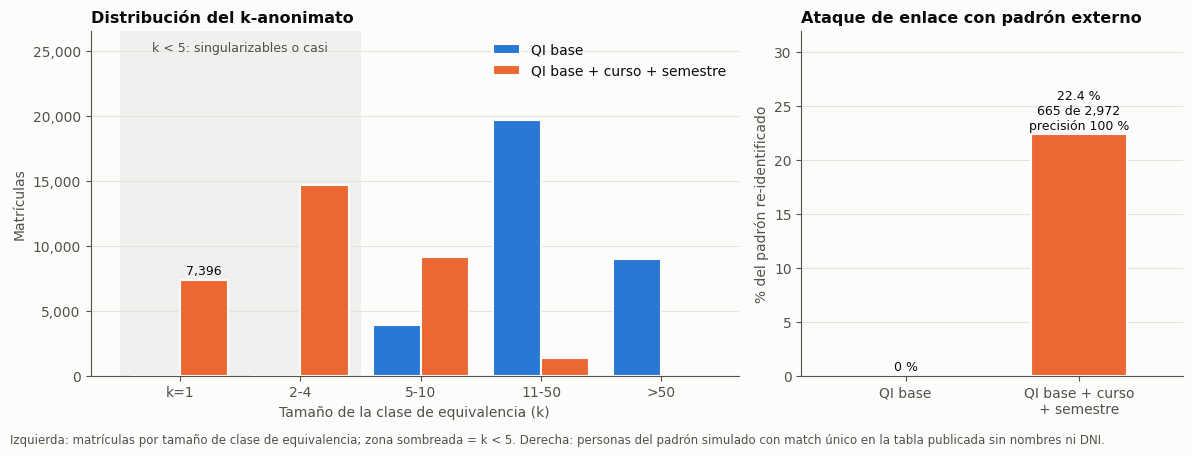

In [18]:
# Figura: distribución de k y resultado del ataque de enlace.
tramos = pd.DataFrame({
    "QI base": pd.cut(df["k_base"], bins, labels=labels).value_counts().sort_index(),
    "QI base + curso + semestre": pd.cut(df["k_ext"], bins, labels=labels).value_counts().sort_index(),
})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1.7, 1]})
x = np.arange(len(labels))
ancho = 0.4
for j, (col, color) in enumerate([("QI base", SERIE_1), ("QI base + curso + semestre", SERIE_2)]):
    ax1.bar(x + (j - 0.5) * ancho, tramos[col], width=ancho, color=color, edgecolor=FONDO, linewidth=1.5, label=col)
ax1.axvspan(-0.5, 1.5, color=REJILLA, alpha=0.45, linewidth=0, zorder=0)
techo = tramos.to_numpy().max() * 1.35
ax1.set_ylim(0, techo)
ax1.text(0.5, techo * 0.94, "k < 5: singularizables o casi", ha="center", fontsize=9, color=TINTA_2)
ax1.annotate(f"{tramos.loc['k=1', 'QI base + curso + semestre']:,}", (x[0] + 0.5 * ancho, tramos.loc["k=1", "QI base + curso + semestre"]),
             xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9, color=TINTA)
ax1.set_xticks(x, labels)
ax1.set_xlabel("Tamaño de la clase de equivalencia (k)")
ax1.set_ylabel("Matrículas")
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax1.set_title("Distribución del k-anonimato")
ax1.legend(loc="upper right")

pct = [m_base["% re-identificación"], m_ext["% re-identificación"]]
ax2.bar([0, 1], pct, width=0.55, color=[SERIE_1, SERIE_2], edgecolor=FONDO, linewidth=1.5)
ax2.annotate(f"{pct[0]:.0f} %", (0, pct[0]), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9)
ax2.annotate(f"{pct[1]:.1f} %\n{m_ext['re-identificados (match único)']:,} de {m_ext['objetivos en padrón']:,}\n"
             f"precisión {m_ext['precisión del match único']:.0f} %",
             (1, pct[1]), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9)
ax2.set_xticks([0, 1], ["QI base", "QI base + curso\n+ semestre"])
ax2.set_xlim(-0.6, 1.6)
ax2.set_ylim(0, 32)
ax2.set_ylabel("% del padrón re-identificado")
ax2.set_title("Ataque de enlace con padrón externo")

fig.text(0.01, -0.02, "Izquierda: matrículas por tamaño de clase de equivalencia; zona sombreada = k < 5. "
         "Derecha: personas del padrón simulado con match único en la tabla publicada sin nombres ni DNI.",
         fontsize=8.5, color=TINTA_2)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/distribucion_k_y_enlace.png", dpi=200, bbox_inches="tight")
plt.show()

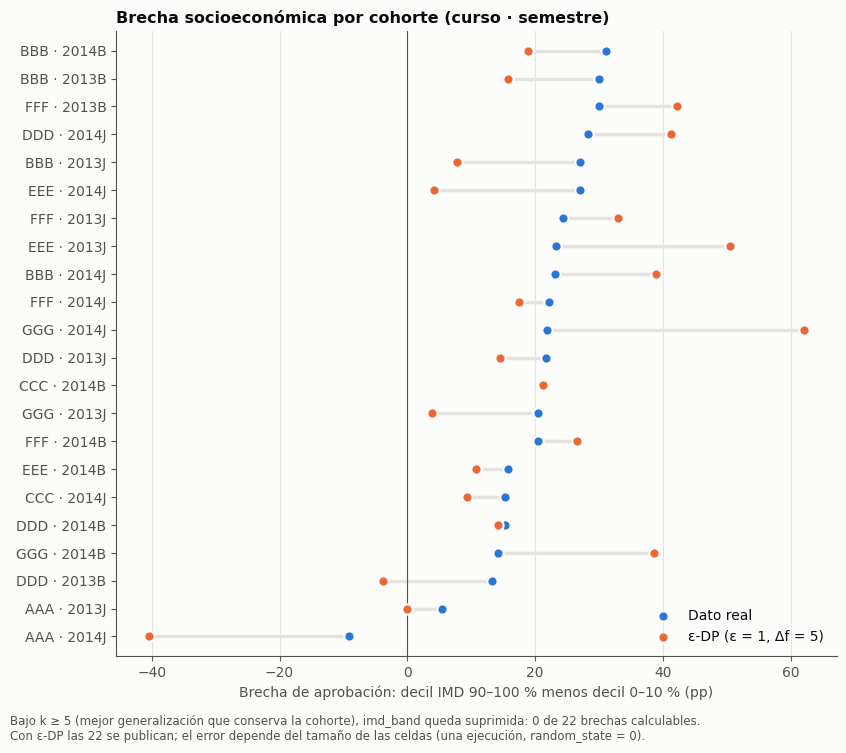

In [19]:
# Figura: brecha socioeconómica por cohorte, dato real frente a ε-DP.
d = comp.sort_values("brecha_real_pp")
pos = np.arange(len(d))
fig, ax = plt.subplots(figsize=(8.5, 7.2))
ax.grid(False)
ax.grid(axis="x")
ax.hlines(pos, d[["brecha_real_pp", "brecha_dp_pp"]].min(axis=1), d[["brecha_real_pp", "brecha_dp_pp"]].max(axis=1),
          color=REJILLA, linewidth=2.5, zorder=1)
ax.scatter(d["brecha_real_pp"], pos, s=55, color=SERIE_1, edgecolor=FONDO, linewidth=1.5, zorder=3, label="Dato real")
ax.scatter(d["brecha_dp_pp"], pos, s=55, color=SERIE_2, edgecolor=FONDO, linewidth=1.5, zorder=3,
           label=f"ε-DP (ε = {EPSILON:g}, Δf = {DELTA_F})")
ax.axvline(0, color=TINTA_2, linewidth=0.8)
ax.set_yticks(pos, [f"{m} · {p}" for m, p in d.index])
ax.set_ylim(-0.7, len(d) - 0.3)
ax.set_xlabel("Brecha de aprobación: decil IMD 90–100 % menos decil 0–10 % (pp)")
ax.set_title("Brecha socioeconómica por cohorte (curso · semestre)")
ax.legend(loc="lower right")
fig.text(0.01, -0.035, "Bajo k ≥ 5 (mejor generalización que conserva la cohorte), imd_band queda suprimida: 0 de 22 brechas calculables.\n"
         "Con ε-DP las 22 se publican; el error depende del tamaño de las celdas (una ejecución, random_state = 0).",
         fontsize=8.5, color=TINTA_2)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/brecha_imd_real_vs_dp.png", dpi=200, bbox_inches="tight")
plt.show()

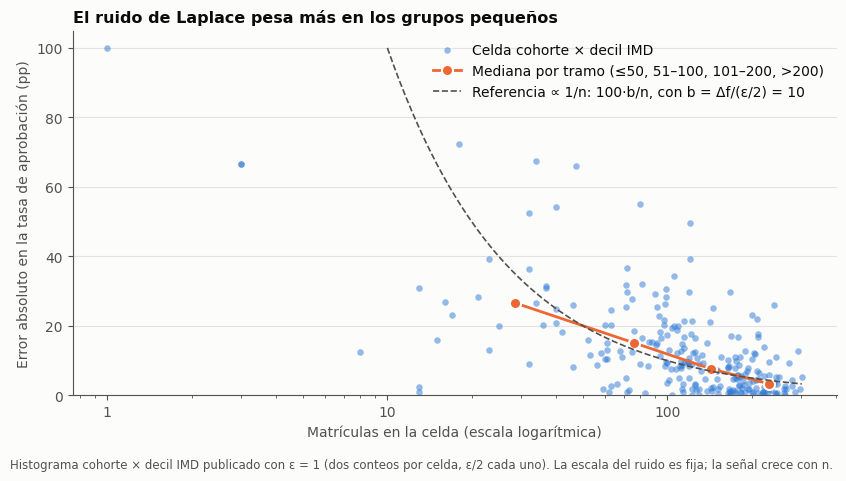

In [20]:
# Figura: error de la tasa DP frente al tamaño de la celda.
b = DELTA_F / (EPSILON / 2)
med = conteos.groupby("tamaño_celda", observed=True).agg(n=("n", "median"), error=("error_pp", "median"))
nn = np.geomspace(10, conteos["n"].max(), 200)

fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.scatter(conteos["n"], conteos["error_pp"], s=22, color=SERIE_1, alpha=0.5, linewidth=0,
           label="Celda cohorte × decil IMD")
ax.plot(med["n"], med["error"], color=SERIE_2, marker="o", markersize=8, markeredgecolor=FONDO, markeredgewidth=1.5,
        label="Mediana por tramo (≤50, 51–100, 101–200, >200)")
ax.plot(nn, 100 * b / nn, color=TINTA_2, linestyle="--", linewidth=1.2,
        label=f"Referencia ∝ 1/n: 100·b/n, con b = Δf/(ε/2) = {b:g}")
ax.set_xscale("log")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_ylim(0, 105)
ax.set_xlabel("Matrículas en la celda (escala logarítmica)")
ax.set_ylabel("Error absoluto en la tasa de aprobación (pp)")
ax.set_title("El ruido de Laplace pesa más en los grupos pequeños")
ax.legend(loc="upper right")
fig.text(0.01, -0.03, f"Histograma cohorte × decil IMD publicado con ε = {EPSILON:g} (dos conteos por celda, ε/2 cada uno). "
         "La escala del ruido es fija; la señal crece con n.", fontsize=8.5, color=TINTA_2)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/error_dp_vs_tamano_celda.png", dpi=200, bbox_inches="tight")
plt.show()

In [21]:
con.close()